# 02 Model comparison

Compares every ONI forecast model on the same split and the same metrics, then scores them once on the test years.
All the logic lives in `backend/app/layer1_forecast/train.py`; this notebook only shows the results. It saves nothing.
To save the model, run `python -m app.layer1_forecast.train` from `backend/`.

**Read these before the tables:**
- **Rows per lead.** Each lead is scored only on rows where its target month has an observed ONI. The newest anchor months have no observed future yet, so longer leads are scored on fewer test rows. The `rows` column shows the count.
- **Which model the test scores describe.** Test scores come from models fitted on **1950 to 2016**. The saved model is refitted on all data up to 2026, so the test scores are an estimate for it, not an exact measurement.
- **Few events.** The test years hold only four El Nino events, one still ongoing. Treat all scores as rough.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path("../backend").resolve()))  # so `app` can be imported

from app.layer1_forecast.models import load_enso_monthly
from app.layer1_forecast.train import event_summary, run_comparison

table = load_enso_monthly()
results = run_comparison(table)
best = results["best"]

## 1. Validation (fitted on 1950 to 2008, scored on 2009 to 2016)

`persistence` is a reference with no training: the forecast for every lead is the newest ONI.

In [2]:
validation = results["validation"]["regression"]
print("Validation RMSE by lead (lower is better)")
print(validation.pivot(index="model", columns="lead", values="rmse").round(3).to_string())
print()
print("Validation MAE by lead (lower is better)")
print(validation.pivot(index="model", columns="lead", values="mae").round(3).to_string())

Validation RMSE by lead (lower is better)
lead                   1      2      3      4      5      6
model                                                      
linear_regression  0.130  0.296  0.456  0.587  0.690  0.771
persistence        0.228  0.441  0.633  0.800  0.943  1.063
random_forest      0.192  0.375  0.554  0.695  0.759  0.791
xgboost            0.190  0.344  0.510  0.627  0.715  0.766

Validation MAE by lead (lower is better)
lead                   1      2      3      4      5      6
model                                                      
linear_regression  0.109  0.247  0.367  0.459  0.528  0.579
persistence        0.186  0.357  0.506  0.634  0.739  0.832
random_forest      0.154  0.299  0.443  0.544  0.571  0.590
xgboost            0.145  0.274  0.406  0.498  0.544  0.572


## 2. Chosen model

Rule: the lowest mean validation RMSE across leads 1 to 6, one model for all leads. The choice is made here, before any test score exists.

In [3]:
print(validation.groupby("model")["rmse"].mean().sort_values().round(3).to_string())
print()
print("Chosen model:", best)

model
linear_regression    0.488
xgboost              0.525
random_forest        0.561
persistence          0.685

Chosen model: linear_regression


## 3. Test years, scored once (models fitted on 1950 to 2016, scored on 2017 to 2026)

Each lead is scored only on test rows whose target is observed (see the `rows` table).

In [4]:
test = results["test"]["regression"]
print("Test RMSE by lead")
print(test.pivot(index="model", columns="lead", values="rmse").round(3).to_string())
print()
print("Test MAE by lead")
print(test.pivot(index="model", columns="lead", values="mae").round(3).to_string())
print()
print("Test rows scored per lead")
print(test.query("model == @best").set_index("lead")["rows"].to_string())

Test RMSE by lead
lead                   1      2      3      4      5      6
model                                                      
linear_regression  0.107  0.239  0.371  0.488  0.587  0.664
persistence        0.189  0.364  0.523  0.665  0.789  0.893
random_forest      0.130  0.250  0.389  0.503  0.605  0.695
xgboost            0.127  0.266  0.397  0.518  0.624  0.696

Test MAE by lead
lead                   1      2      3      4      5      6
model                                                      
linear_regression  0.086  0.196  0.303  0.399  0.484  0.550
persistence        0.158  0.301  0.429  0.538  0.624  0.700
random_forest      0.105  0.203  0.318  0.406  0.481  0.544
xgboost            0.105  0.217  0.324  0.424  0.510  0.565

Test rows scored per lead
lead
1    116
2    115
3    114
4    113
5    112
6    111


In [5]:
status = results["test"]["status"]
print("Test status accuracy by lead (higher is better)")
print(status.pivot(index="model", columns="lead", values="accuracy").round(3).to_string())
for lead in (1, 6):
    print()
    print(f"Logistic regression confusion matrix on test, lead {lead}")
    print(results["test"]["confusion"][lead].to_string())

Test status accuracy by lead (higher is better)
lead                     1      2      3      4      5      6
model                                                        
logistic_regression  0.922  0.809  0.711  0.637  0.536  0.514
most_common_class    0.440  0.435  0.430  0.425  0.420  0.414

Logistic regression confusion matrix on test, lead 1
              pred La Nina  pred Neutral  pred El Nino
true La Nina            29             4             0
true Neutral             1            49             1
true El Nino             0             3            29

Logistic regression confusion matrix on test, lead 6
              pred La Nina  pred Neutral  pred El Nino
true La Nina             5            28             0
true Neutral             4            40             2
true El Nino             0            20            12


## 4. Event detection on the test years (chosen model)

For each lead, the forecast series is the prediction for every month made that many months earlier. A true event counts as detected when an event in that series overlaps it. The series keeps its forecast months past the newest observation (September 2026), so the ongoing event can be found at every lead.
Start error is predicted start minus true start, in months. Duration error is left empty for the ongoing 2026 event, because its final length is not known.

In [6]:
events = results["events"]
print(events.to_string(index=False))
print()
print(event_summary(events).round(2).to_string())

 lead event_start  ongoing  true_duration  detected predicted_start  start_error_months  duration_error_months
    1     2018-09    False             10      True         2018-10                 1.0                   -1.0
    1     2019-10    False              6      True         2019-11                 1.0                   -1.0
    1     2023-06    False             11      True         2023-06                 0.0                    0.0
    1     2026-05     True              5      True         2026-05                 0.0                    NaN
    2     2018-09    False             10      True         2018-11                 2.0                   -2.0
    2     2019-10    False              6     False             NaN                 NaN                    NaN
    2     2023-06    False             11      True         2023-07                 1.0                    0.0
    2     2026-05     True              5      True         2026-06                 1.0                    NaN
 

## 5. Predicted vs actual ONI on the test years

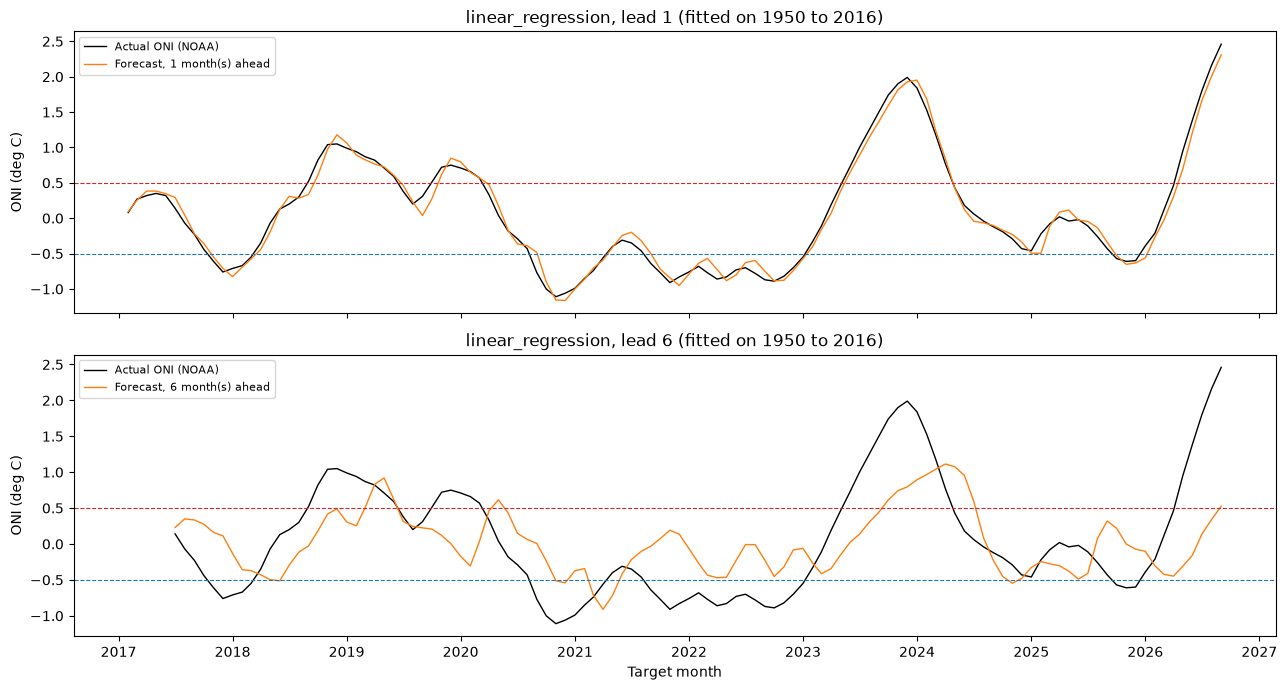

In [7]:
predictions = results["test_predictions"]
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, lead in zip(axes, (1, 6)):
    part = predictions[predictions["lead"] == lead].dropna(subset=["actual"])
    ax.plot(part["target_month"], part["actual"], color="black", linewidth=1, label="Actual ONI (NOAA)")
    ax.plot(part["target_month"], part["predicted"], color="tab:orange", linewidth=1, label=f"Forecast, {lead} month(s) ahead")
    ax.axhline(0.5, color="tab:red", linestyle="--", linewidth=0.8)
    ax.axhline(-0.5, color="tab:blue", linestyle="--", linewidth=0.8)
    ax.set_ylabel("ONI (deg C)")
    ax.set_title(f"{best}, lead {lead} (fitted on 1950 to 2016)")
    ax.legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("Target month")
plt.tight_layout()
plt.show()